# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** K. Satya Ganesh

**Roll Number:** AP24110010736

**Date:** 09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [2]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


*Your answer:*

A 70/30 split has higher entropy than a 90/10 split because the two classes are more balanced. It is harder to guess the label in the 70/30 case.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [7]:
# Entropy of the parent and information gain of the split
parent_entropy = entropy([8, 6])
left_entropy = entropy([6, 0])
right_entropy = entropy([2, 6])

weighted_entropy = (6 / 14) * left_entropy + (8 / 14) * right_entropy
gain = parent_entropy - weighted_entropy

print("Parent entropy:", round(parent_entropy, 4))
print("Left child entropy:", round(left_entropy, 4))
print("Right child entropy:", round(right_entropy, 4))
print("Information gain:", round(gain, 4))

Parent entropy: 0.9852
Left child entropy: 0.0
Right child entropy: 0.8113
Information gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [4]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [16]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [17]:
# Calculate information gain for the three attributes
for attribute in ['Outlook', 'Temperature', 'Humidity']:
    print(f"Gain({attribute}):", round(info_gain(tennis, attribute), 4))

# The attribute with the highest information gain is selected as the root
gains = {attribute: info_gain(tennis, attribute)
         for attribute in ['Outlook', 'Temperature', 'Humidity']}
root = max(gains, key=gains.get)
print("Root attribute:", root)

# Outlook is the root. Check the branch that is not pure.
sunny_branch = tennis[tennis['Outlook'] == 'Sunny']
print("\nGains for the Sunny branch:")
for attribute in ['Temperature', 'Humidity', 'Wind']:
    print(f"Gain({attribute}):", round(info_gain(sunny_branch, attribute), 4))

Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518
Root attribute: Outlook

Gains for the Sunny branch:
Gain(Temperature): 0.571
Gain(Humidity): 0.971
Gain(Wind): 0.02


**Reflection:** `Overcast` is a pure branch because all the examples in that branch have the same label, `Yes`. There is no need to ask another question because the prediction is already clear.

## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


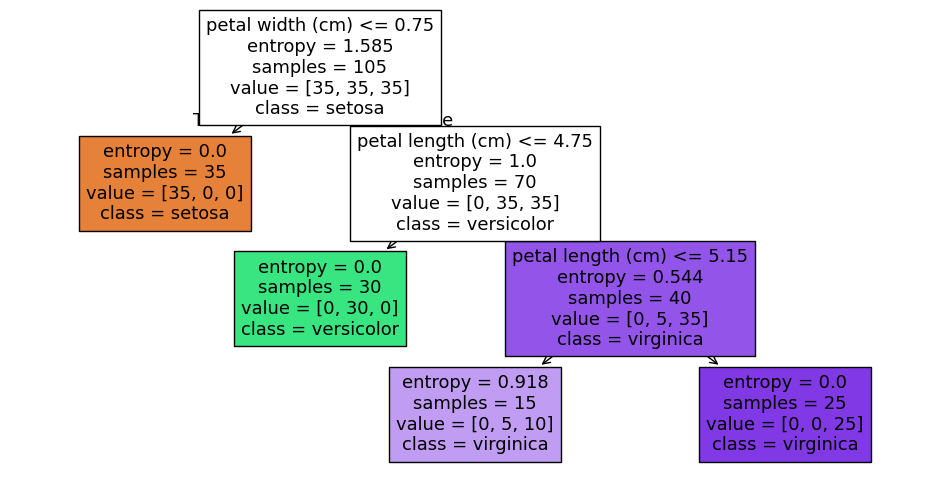

In [18]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


,max_depth,train_accuracy,test_accuracy
0,1,0.666667,0.666667
1,2,0.952381,0.955556
2,3,0.952381,0.955556
3,4,0.952381,0.933333
4,5,0.971429,0.977778
5,6,0.980952,0.977778
6,7,0.980952,0.977778
7,8,0.990476,0.977778
8,9,1.000000,0.977778
9,10,1.000000,0.977778


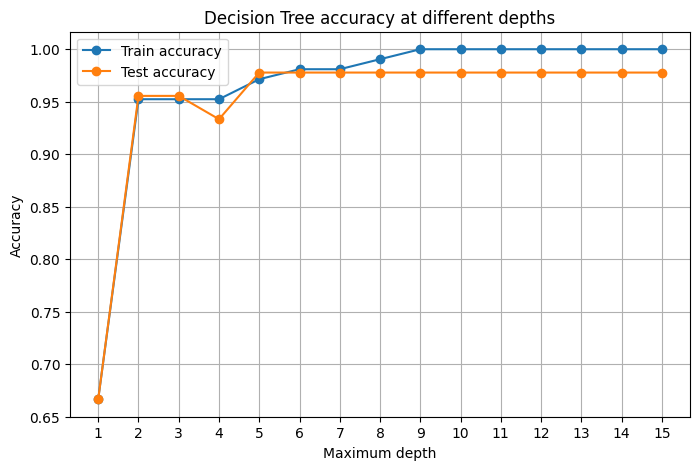

Depth with best test accuracy: 5
Best test accuracy: 0.9778


In [19]:
# Compare training and test accuracy for different tree depths
depths = list(range(1, 16))
train_scores = []
test_scores = []

for depth in depths:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    model.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test)))

results = pd.DataFrame({
    'max_depth': depths,
    'train_accuracy': train_scores,
    'test_accuracy': test_scores
})
display(results)

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Train accuracy')
plt.plot(depths, test_scores, marker='o', label='Test accuracy')
plt.xlabel('Maximum depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree accuracy at different depths')
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[int(np.argmax(test_scores))]
print("Depth with best test accuracy:", best_depth)
print("Best test accuracy:", round(max(test_scores), 4))

*Your answer:*

The polynomial degree in Week 6 and the value of K in Week 7 played a similar role. If the model is too simple, it may underfit. If it is too complex, it may overfit and perform worse on new data.

# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [20]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Decision Tree test accuracy: 0.8815
No scaling is needed because decision trees split using feature thresholds, not distances.
max_depth=3: test accuracy = 0.5296
max_depth=6: test accuracy = 0.8537
max_depth=10: test accuracy = 0.8796


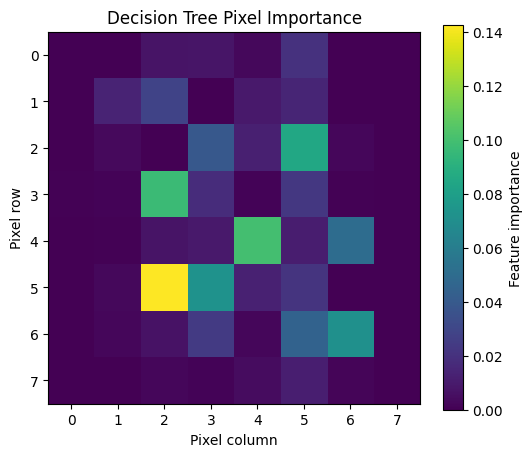

The tree uses the pixels with the highest importance values most often for its splits.


In [21]:
# 1. Fit a decision tree on the unscaled digits data
digits_tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
digits_tree.fit(Xd_train, yd_train)
print("Decision Tree test accuracy:", round(accuracy_score(yd_test, digits_tree.predict(Xd_test)), 4))
print("No scaling is needed because decision trees split using feature thresholds, not distances.")

# 2. Compare different maximum depths
for depth in [3, 6, 10]:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    model.fit(Xd_train, yd_train)
    score = accuracy_score(yd_test, model.predict(Xd_test))
    print(f"max_depth={depth}: test accuracy = {score:.4f}")

# 3. Show the importance of each pixel as an 8 by 8 image
importance_tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
importance_tree.fit(Xd_train, yd_train)
importance_map = importance_tree.feature_importances_.reshape(8, 8)

plt.figure(figsize=(6, 5))
plt.imshow(importance_map, cmap='viridis')
plt.colorbar(label='Feature importance')
plt.title('Decision Tree Pixel Importance')
plt.xlabel('Pixel column')
plt.ylabel('Pixel row')
plt.show()

print("The tree uses the pixels with the highest importance values most often for its splits.")

*Reflection:*

The decision tree is usually less accurate than KNN on the digits data. A tree makes splits using individual pixels, while KNN compares the overall distance between images. The importance map also shows that the tree mainly relies on some pixels rather than treating all pixels equally.

# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [22]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [15]:
# Train a decision tree for the sentence topics
text_tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
text_tree.fit(X_text, labels)

print(export_text(text_tree, feature_names=vocab))

# Predict the topic of a new sentence
new_sentence = 'the striker scored a goal'
new_vector = to_vector(new_sentence, vocab).reshape(1, -1)
print("Topic of new sentence:", text_tree.predict(new_vector)[0])

# My own sentence
my_sentence = 'the team has a new phone'
my_vector = to_vector(my_sentence, vocab).reshape(1, -1)
print("My sentence:", my_sentence)
print("Predicted topic:", text_tree.predict(my_vector)[0])

|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

Topic of new sentence: sports
My sentence: the team has a new phone
Predicted topic: tech


**Reflection:**

The split words could change if we add more sentences because the tree learns patterns from the examples it receives. With only a few sentences, one or two examples can affect the result a lot. So, a tree trained on very little data may not make reliable predictions for every new sentence.

## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
